In [14]:
from google.colab import files
uploaded = files.upload()

Saving hiv_prevalence.csv to hiv_prevalence.csv


In [42]:
import pandas as pd
import numpy as np

# Baca file CSV dengan separator yang benar
df = pd.read_csv("hiv_prevalence.csv", sep=';', encoding='latin1')

# Tampilkan kolom untuk ngecek
print(df.columns)
print("Columns after stripping whitespace:")
print(df.columns.tolist())
df.columns = df.columns.str.strip()
df.head()

Index(['Country/Region,', 'Adult prevalence', 'Number of people',
       'Annual deaths', 'Year of estimate'],
      dtype='object')
Columns after stripping whitespace:
['Country/Region,', 'Adult prevalence', 'Number of people', 'Annual deaths', 'Year of estimate']


,"Country/Region,",Adult prevalence,Number of people,Annual deaths,Year of estimate
0,NaN,"of HIV/AIDS,","with HIV/AIDS,","from HIV/AIDS,",NaN
1,Eswatini,28.30%,"240,000","3,000",2024
2,Lesotho,24.10%,"403,000","5,380",2024
3,Botswana,22.60%,"398,500","5,240",2024
4,Zimbabwe,22.10%,"1,660,000","25,600",2024


In [52]:
import numpy as np
import pandas as pd

# Bersihkan nama kolom
df.columns = ['Country_Region', 'Adult_Prevalence', 'Num_People', 'Annual_Deaths', 'Year_of_estimate']

# Strip whitespace
df = df.apply(lambda x: x.str.strip() if x.dtype == "object" else x)

# Ganti tanda '-' jadi NaN
df.replace('-', np.nan, inplace=True)

# Hapus persen & koma, ubah ke float
for col in ['Adult_Prevalence', 'Num_People', 'Annual_Deaths']:
    if col in df.columns:
        df[col] = df[col].astype(str).str.replace('%', '', regex=False)
        df[col] = df[col].str.replace(',', '', regex=False)
        df[col] = pd.to_numeric(df[col], errors='coerce')
    else:
        print(f"Column '{col}' not found in the DataFrame.")

# Ubah Year_of_estimate ke integer nullable
if 'Year_of_estimate' in df.columns:
    df['Year_of_estimate'] = pd.to_numeric(df['Year_of_estimate'], errors='coerce').astype('Int64')
else:
    print("Column 'Year_of_estimate' not found.")

# Buang baris yang NaN
df_clean = df.dropna()

df_clean.head()

,Country_Region,Adult_Prevalence,Num_People,Annual_Deaths,Year_of_estimate
1,Eswatini,28.3,240000.0,3000.0,2024
2,Lesotho,24.1,403000.0,5380.0,2024
3,Botswana,22.6,398500.0,5240.0,2024
4,Zimbabwe,22.1,1660000.0,25600.0,2024
5,South Africa,14.0,9230000.0,77000.0,2024


In [53]:
# Input features dan target
X = df_clean[['Adult_Prevalence', 'Annual_Deaths', 'Year_of_estimate']]
y = df_clean['Num_People']

In [54]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [55]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

In [56]:
from xgboost import XGBRegressor

model = XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.1, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=5, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=100, n_jobs=None,
             num_parallel_tree=None, random_state=42, ...)

In [59]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R² Score: {r2:.2f}")

MAE: 90108.24
RMSE: 117648.63
R² Score: 0.91


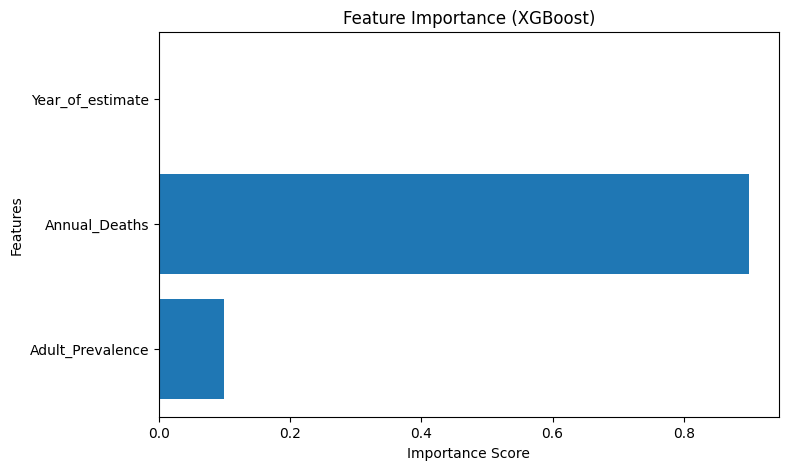

In [58]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.barh(X.columns, model.feature_importances_)
plt.title("Feature Importance (XGBoost)")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()